# Basic tutorial: ``GromovWasserstein`` class

This tutorial compares Reeb graphs with the Gromov-Wasserstein (GW) distance, following

- Erin W. Chambers and Guangyu Meng. *Reeb Graph Comparison via the Gromov-Wasserstein Distance.*

Each Reeb graph $R_f$ is turned into a metric-measure space $\Phi(R_f) = (V_{R_f}, d_{R_f}, \nu_{R_f})$, where $d_{R_f}$ is the **Symmetric Reeb Radius** and $\nu_{R_f}$ is a probability measure on the vertices built from the **Persistence Image** of the extended persistence diagram. The two metric-measure spaces are then compared with the GW distance, computed with the [POT](https://pythonot.github.io/) library.

In [1]:
from cereeberus import ReebGraph, GromovWasserstein, gromov_wasserstein_distance
from cereeberus.distance.gromov_wasserstein import (
    symmetric_reeb_radius,
    extended_persistence_pairs,
    pi_measure,
    persistence_image,
)
import cereeberus.data.ex_mappergraphs as ex_mg

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## The worked example

We start with the two Reeb graphs $R_f$ and $R_g$ of the worked example in the paper.

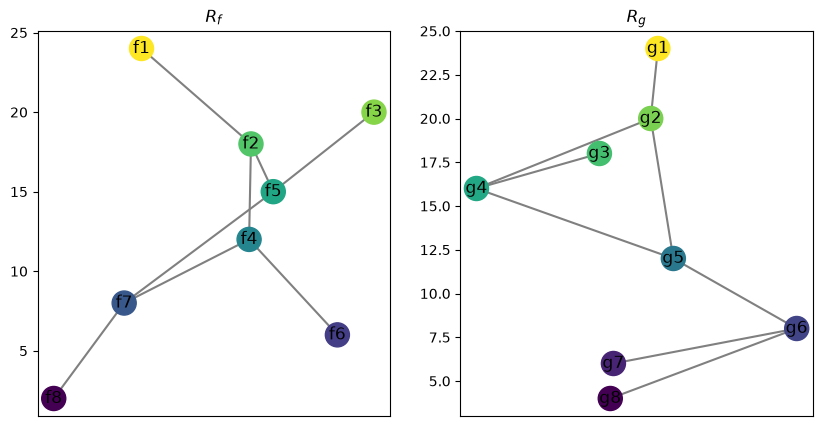

In [2]:
F = ReebGraph()
for v, fv in {'f1': 24, 'f2': 18, 'f3': 20, 'f4': 12, 'f5': 15, 'f6': 6, 'f7': 8, 'f8': 2}.items():
    F.add_node(v, fv)
F.add_edges_from([('f1', 'f2'), ('f2', 'f4'), ('f2', 'f5'), ('f3', 'f5'),
                  ('f5', 'f7'), ('f4', 'f6'), ('f4', 'f7'), ('f7', 'f8')])
F.set_pos_from_f(seed=3)

G = ReebGraph()
for v, gv in {'g1': 24, 'g2': 20, 'g3': 18, 'g4': 16, 'g5': 12, 'g6': 8, 'g7': 6, 'g8': 4}.items():
    G.add_node(v, gv)
G.add_edges_from([('g1', 'g2'), ('g2', 'g4'), ('g4', 'g3'), ('g2', 'g5'),
                  ('g4', 'g5'), ('g5', 'g6'), ('g6', 'g7'), ('g6', 'g8')])
G.set_pos_from_f(seed=3)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
F.draw(ax=ax[0])
ax[0].set_title('$R_f$')
G.draw(ax=ax[1])
ax[1].set_title('$R_g$');

## Step 1: the Symmetric Reeb Radius

The Reeb radius from $u$ to $v$ is the smallest possible largest deviation from $f(u)$ along a path from $u$ to $v$,
$$\rho_f(u, v) = \inf_{\gamma: u \to v} \sup_{t} |f(u) - f(\gamma(t))|.$$
It is not symmetric, so we average the two directions:
$$d_{R_f}(u, v) = \tfrac{1}{2}\left(\rho_f(u, v) + \rho_f(v, u)\right).$$
The function ``symmetric_reeb_radius`` returns this matrix as a ``pandas.DataFrame``. Passing ``method='max'`` uses $\max(\rho_f(u, v), \rho_f(v, u))$ instead.

In [3]:
symmetric_reeb_radius(F)

,f1,f2,f3,f4,f5,f6,f7,f8
f1,0.0,6.0,7.0,12.0,9.0,18.0,16.0,22.0
f2,6.0,0.0,4.0,6.0,3.0,12.0,10.0,16.0
f3,7.0,4.0,0.0,8.0,5.0,14.0,12.0,18.0
f4,12.0,6.0,8.0,0.0,3.5,6.0,4.0,10.0
f5,9.0,3.0,5.0,3.5,0.0,9.0,7.0,13.0
f6,18.0,12.0,14.0,6.0,9.0,0.0,5.0,8.0
f7,16.0,10.0,12.0,4.0,7.0,5.0,0.0,6.0
f8,22.0,16.0,18.0,10.0,13.0,8.0,6.0,0.0


In [4]:
symmetric_reeb_radius(G)

,g1,g2,g3,g4,g5,g6,g7,g8
g1,0.0,4.0,7.0,8.0,12.0,16.0,18.0,20.0
g2,4.0,0.0,3.0,4.0,8.0,12.0,14.0,16.0
g3,7.0,3.0,0.0,2.0,6.0,10.0,12.0,14.0
g4,8.0,4.0,2.0,0.0,4.0,8.0,10.0,12.0
g5,12.0,8.0,6.0,4.0,0.0,4.0,6.0,8.0
g6,16.0,12.0,10.0,8.0,4.0,0.0,2.0,4.0
g7,18.0,14.0,12.0,10.0,6.0,2.0,0.0,3.0
g8,20.0,16.0,14.0,12.0,8.0,4.0,3.0,0.0


## Step 2: the Persistence Image based measure

First we compute the extended persistence diagram, together with the two vertices that realize each pair. The four types of pairs are ordinary ($\mathrm{Ord}_0$), relative ($\mathrm{Rel}_1$) and extended ($\mathrm{Ext}_0$, $\mathrm{Ext}_1$).

In [5]:
columns = ['birth vertex', 'death vertex', 'birth', 'death', 'type']
pd.DataFrame(extended_persistence_pairs(F), columns=columns)

,birth vertex,death vertex,birth,death,type
0,f6,f4,6.0,12.0,Ord0
1,f8,f1,2.0,24.0,Ext0
2,f3,f5,20.0,15.0,Rel1
3,f2,f7,18.0,8.0,Ext1


In [6]:
pd.DataFrame(extended_persistence_pairs(G), columns=columns)

,birth vertex,death vertex,birth,death,type
0,g7,g6,6.0,8.0,Ord0
1,g8,g1,4.0,24.0,Ext0
2,g3,g4,18.0,16.0,Rel1
3,g2,g5,20.0,12.0,Ext1


Each pair $(b, d)$ becomes the point $(b, |d - b|)$ in the birth-persistence plane, and the Persistence Image is a sum of Gaussians with bandwidth $\sigma$ centered at these points, weighted by $|d - b|^{w_p}$.

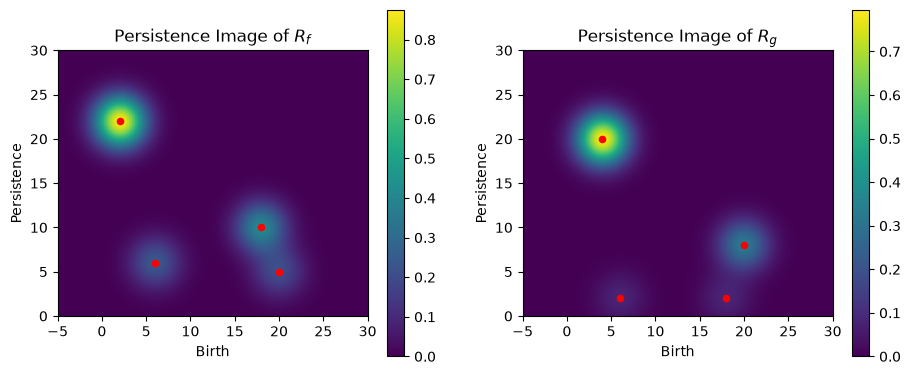

In [7]:
sigma = 2
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for axis, R, name in zip(ax, [F, G], ['$R_f$', '$R_g$']):
    points = np.array([(b, abs(d - b)) for _, _, b, d, _ in extended_persistence_pairs(R)])
    image, centers = persistence_image(points, sigma, birth_range=(-5, 30), pers_range=(0, 30), resolution=200)
    im = axis.imshow(image, origin='lower', extent=(-5, 30, 0, 30), cmap='viridis')
    axis.scatter(points[:, 0], points[:, 1], c='red', s=20)
    axis.set_xlabel('Birth')
    axis.set_ylabel('Persistence')
    axis.set_title(f'Persistence Image of {name}')
    fig.colorbar(im, ax=axis)

The mass of a vertex is proportional to the inner product of the Persistence Image with the Gaussian centered at the point of its pair. Both vertices of a pair get the same mass, and the vertices of highly persistent pairs get the most mass.

In [8]:
mu_F = pi_measure(F, sigma=2, resolution=500)
mu_G = pi_measure(G, sigma=2, resolution=500)
pd.DataFrame({'nu_Rf': mu_F.values(), 'nu_Rg': mu_G.values()},
             index=[f'{u} / {v}' for u, v in zip(mu_F, mu_G)]).round(4)

,nu_Rf,nu_Rg
f1 / g1,0.242,0.3075
f2 / g2,0.119,0.1255
f3 / g3,0.073,0.0385
f4 / g4,0.066,0.0385
f5 / g5,0.073,0.1255
f6 / g6,0.066,0.0284
f7 / g7,0.119,0.0284
f8 / g8,0.242,0.3075


## Step 3: the Gromov-Wasserstein distance

The ``GromovWasserstein`` class puts the two steps together and computes the distance with POT. The value returned is the GW objective with the square loss,
$$\sum_{x, x', y, y'} |d_{R_f}(x, x') - d_{R_g}(y, y')|^2 \, \pi(x, y) \, \pi(x', y').$$

By default the two Persistence Images are computed on one shared pixel grid. The worked example in the paper computed each image on a grid fitted to its own diagram; ``shared_grid=False`` reproduces that, and gives the reported value $GW_2 \approx 7.815$.

In [9]:
myGW = GromovWasserstein(F, G, sigma=2, resolution=500, shared_grid=False)
myGW.fit()

7.81468756615448

In [10]:
# With the default shared grid the measures change by less than 1e-5
GromovWasserstein(F, G, sigma=2, resolution=500).fit()

7.814241101486035

The optimal transport plan is stored in ``myGW.plan``, with the vertices of $R_f$ as rows and those of $R_g$ as columns. It gives a correspondence between the vertices of the two graphs.

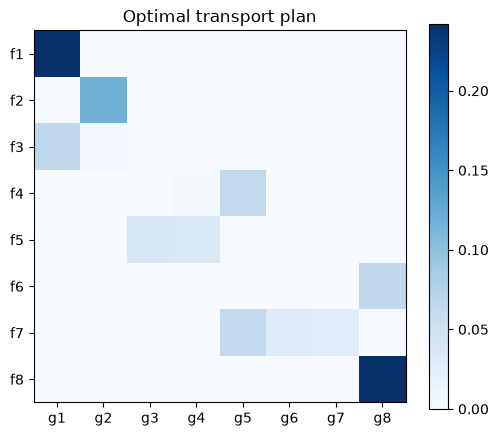

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(myGW.plan, cmap='Blues')
ax.set_xticks(range(len(myGW.plan.columns)), myGW.plan.columns)
ax.set_yticks(range(len(myGW.plan.index)), myGW.plan.index)
ax.set_title('Optimal transport plan')
fig.colorbar(im, ax=ax);

## Comparing Mapper graphs

``MapperGraph`` objects can be compared in the same way; their function values are scaled by ``delta``. Without parameters, the bandwidth is 10% of the largest persistence, the grid has $10 \times 10$ pixels and $w_p = 1$, which is the starting configuration suggested in the paper. Here we compare a few of the example Mapper graphs with the shortcut ``gromov_wasserstein_distance``. The graphs must be connected, since the Reeb radius between two components is infinite; for a graph with several components, such as the juggling man, use ``get_largest_component()`` first.

In [12]:
graphs = {
    'torus': ex_mg.torus(0, 2, 8, 10, delta=1),
    'tall torus': ex_mg.torus(0, 2, 12, 14, delta=1),
    'dancing man': ex_mg.dancing_man(delta=1),
    'simple loops': ex_mg.simple_loops(delta=1),
}
names = list(graphs)
D = pd.DataFrame(0.0, index=names, columns=names)
for i, a in enumerate(names):
    for b in names[i + 1:]:
        D.loc[a, b] = D.loc[b, a] = gromov_wasserstein_distance(graphs[a], graphs[b])
D.round(2)

,torus,tall torus,dancing man,simple loops
torus,0.00,2.36,2.35,7.03
tall torus,2.36,0.00,8.56,16.17
dancing man,2.35,8.56,0.00,2.65
simple loops,7.03,16.17,2.65,0.00
